# Dawn

## Loading the Dataset

In [1]:
import html
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/job_observations.csv")

## First Look

In [3]:
print("Shape :", df.shape)

Shape : (10205, 14)


In [4]:
df.head()

,source,title,company,location,published_at,tags_json,salary_min,salary_max,salary_currency,salary_period,eligible,first_seen_at,last_seen_at,times_seen
0,remoteok,Engineering Manager Thailand,Bjak,Bangkok,2026-08-14T08:00:04+00:00,"[""exec"", ""design"", ""sys admin"", ""front end"", ""...",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
1,remoteok,Quality Checker,InTechNative,"Nellore,",2026-08-14T07:58:11+00:00,"[""infosec"", ""javascript""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
2,remoteok,Current Openings,Black Talon Security,"Swift Current,",2026-08-14T05:27:50+00:00,"[""infosec""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
3,remoteok,Gardener Handyman Driver,NT Health,"Alice Springs,",2026-08-13T20:09:23+00:00,"[""customer support"", ""exec"", ""medical""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
4,remoteok,Express Your Interest,"Alexander &amp; Bebout, Inc.","Van Wert,",2026-08-13T19:49:30+00:00,"[""web dev"", ""hr"", ""sys admin"", ""marketing"", ""n...",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1


## Column Types and Missing Values

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10205 entries, 0 to 10204
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           10205 non-null  str    
 1   title            10205 non-null  str    
 2   company          8935 non-null   str    
 3   location         7335 non-null   str    
 4   published_at     10205 non-null  str    
 5   tags_json        10205 non-null  str    
 6   salary_min       1070 non-null   float64
 7   salary_max       1051 non-null   float64
 8   salary_currency  1229 non-null   str    
 9   salary_period    1965 non-null   str    
 10  eligible         10205 non-null  int64  
 11  first_seen_at    10205 non-null  str    
 12  last_seen_at     10205 non-null  str    
 13  times_seen       10205 non-null  int64  
dtypes: float64(2), int64(2), str(10)
memory usage: 3.7 MB


## Summary Statistics

In [6]:
df.describe()

,salary_min,salary_max,eligible,times_seen
count,1.070000e+03,1.051000e+03,10205.000000,10205.000000
mean,1.140109e+05,1.541928e+05,0.027732,2.623714
std,1.494311e+05,2.215128e+05,0.164211,3.888452
min,4.000000e+00,4.000000e+00,0.000000,1.000000
25%,1.812500e+02,3.250000e+02,0.000000,1.000000
50%,1.025000e+05,1.390000e+05,0.000000,1.000000
75%,1.691750e+05,2.250000e+05,0.000000,3.000000
max,1.800000e+06,2.500000e+06,1.000000,71.000000


## Counting Values

In [7]:
df["source"].value_counts()

source
remoteok          5846
himalayas         1342
jobicy            1318
weworkremotely    1268
jobspy             388
remotive            43
Name: count, dtype: int64

In [8]:
df["eligible"].value_counts()

eligible
0    9922
1     283
Name: count, dtype: int64

In [9]:
df["salary_period"].value_counts(dropna=False)

salary_period
NaN        8240
annual      980
yearly      570
hourly      321
monthly      93
weekly        1
Name: count, dtype: int64

In [10]:
df["salary_currency"].value_counts(dropna=False)

salary_currency
NaN    8976
USD    1006
EUR      71
CAD      48
GBP      27
PLN      24
AUD      17
PHP      12
INR      10
CZK       4
SEK       3
CNY       2
BRL       2
MXN       2
KRW       1
Name: count, dtype: int64

## Cleaning the Needed Columns

In [11]:
raw_title = df["title"].copy()

In [12]:
df["title"] = df["title"].apply(html.unescape)

In [13]:
df["title"] = df["title"].str.replace(r"\s+", " ", regex=True)

In [14]:
df["title"] = df["title"].str.strip()

In [15]:
print("Titles changed :", (df["title"] != raw_title).sum())

Titles changed : 72


In [16]:
df["published_at"] = pd.to_datetime(df["published_at"], format="mixed", utc=True)

In [17]:
df["first_seen_at"] = pd.to_datetime(df["first_seen_at"], utc=True)

In [18]:
df["last_seen_at"] = pd.to_datetime(df["last_seen_at"], utc=True)

In [19]:
df["tags"] = df["tags_json"].apply(json.loads)

In [20]:
df = df.drop(columns="tags_json")

In [21]:
df["salary_period"] = df["salary_period"].replace("yearly", "annual")

## Checking the Clean Data

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10205 entries, 0 to 10204
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   source           10205 non-null  str                
 1   title            10205 non-null  str                
 2   company          8935 non-null   str                
 3   location         7335 non-null   str                
 4   published_at     10205 non-null  datetime64[us, UTC]
 5   salary_min       1070 non-null   float64            
 6   salary_max       1051 non-null   float64            
 7   salary_currency  1229 non-null   str                
 8   salary_period    1965 non-null   str                
 9   eligible         10205 non-null  int64              
 10  first_seen_at    10205 non-null  datetime64[us, UTC]
 11  last_seen_at     10205 non-null  datetime64[us, UTC]
 12  times_seen       10205 non-null  int64              
 13  tags             10205 non-

In [23]:
df.head()

,source,title,company,location,published_at,salary_min,salary_max,salary_currency,salary_period,eligible,first_seen_at,last_seen_at,times_seen,tags
0,remoteok,Engineering Manager Thailand,Bjak,Bangkok,2026-08-14 08:00:04+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[exec, design, sys admin, front end, infosec, ..."
1,remoteok,Quality Checker,InTechNative,"Nellore,",2026-08-14 07:58:11+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[infosec, javascript]"
2,remoteok,Current Openings,Black Talon Security,"Swift Current,",2026-08-14 05:27:50+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,[infosec]
3,remoteok,Gardener Handyman Driver,NT Health,"Alice Springs,",2026-08-13 20:09:23+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[customer support, exec, medical]"
4,remoteok,Express Your Interest,"Alexander &amp; Bebout, Inc.","Van Wert,",2026-08-13 19:49:30+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[web dev, hr, sys admin, marketing, non tech]"


## Postings per Source

In [24]:
source_counts = df["source"].value_counts()
source_counts

source
remoteok          5846
himalayas         1342
jobicy            1318
weworkremotely    1268
jobspy             388
remotive            43
Name: count, dtype: int64

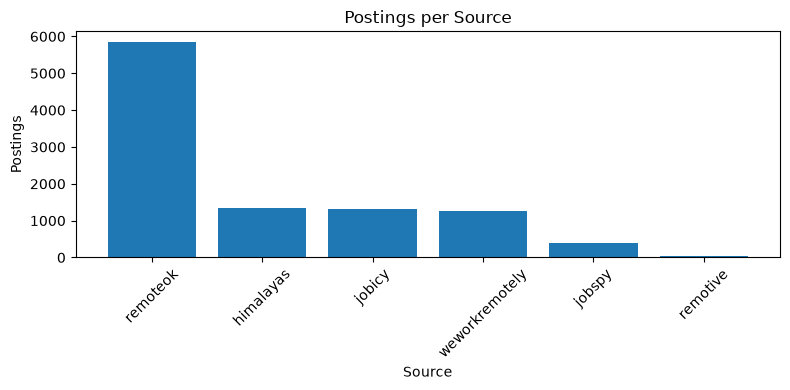

In [25]:
plt.figure(figsize=(8, 4))
plt.bar(source_counts.index, source_counts.values)
plt.xlabel("Source")
plt.ylabel("Postings")
plt.title("Postings per Source")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Eligible Counts

In [26]:
eligible_counts = df["eligible"].value_counts()
eligible_counts

eligible
0    9922
1     283
Name: count, dtype: int64

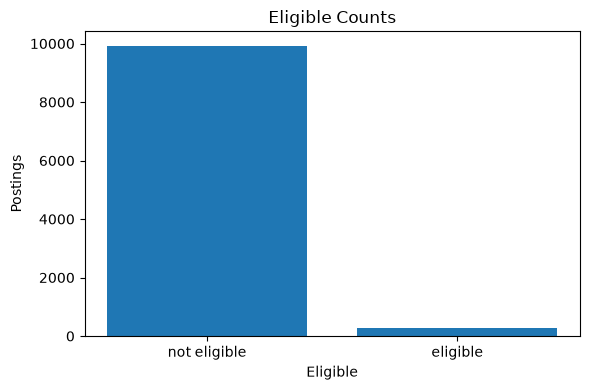

In [27]:
plt.figure(figsize=(6, 4))
plt.bar(["not eligible", "eligible"], eligible_counts.sort_index().values)
plt.xlabel("Eligible")
plt.ylabel("Postings")
plt.title("Eligible Counts")
plt.tight_layout()
plt.show()

## New Postings by Week

In [28]:
week_counts = df["first_seen_at"].dt.tz_convert(None).dt.to_period("W").dt.start_time.value_counts().sort_index()
week_counts

first_seen_at
2026-08-10     241
2026-08-17    1263
2026-08-24     680
2026-08-31    1288
2026-09-07     752
2026-09-14     678
2026-09-21     340
2026-09-28     675
2026-10-05     850
2026-10-12    1122
2026-10-19    1174
2026-10-26     821
2026-11-02     321
Name: count, dtype: int64

In [29]:
print("Busiest week :", week_counts.idxmax().strftime("%Y-%m-%d"), int(week_counts.max()))

Busiest week : 2026-08-31 1288


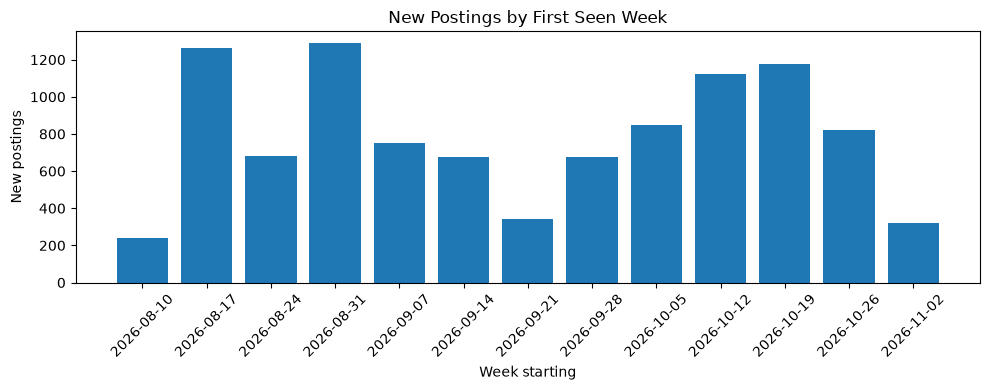

In [30]:
plt.figure(figsize=(10, 4))
plt.bar(week_counts.index.strftime("%Y-%m-%d"), week_counts.values)
plt.xlabel("Week starting")
plt.ylabel("New postings")
plt.title("New Postings by First Seen Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Common Words in Eligible Titles

In [31]:
title_words = df.loc[df["eligible"] == 1, "title"].str.lower()

In [32]:
title_words = title_words.str.replace("[^a-z0-9 ]", " ", regex=True)

In [33]:
title_words = title_words.str.split()

In [34]:
title_words = title_words.explode()

In [35]:
word_counts = title_words.value_counts()
word_counts.head(10)

title
engineer     259
data         168
ai           116
senior        52
machine       41
learning      41
junior        34
scientist     30
platform      28
remote        19
Name: count, dtype: int64

In [36]:
print("Top word :", word_counts.index[0], int(word_counts.iloc[0]))

Top word : engineer 259


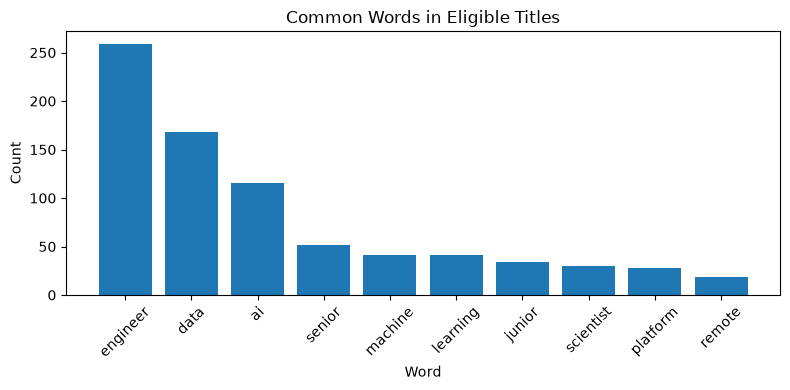

In [37]:
plt.figure(figsize=(8, 4))
plt.bar(word_counts.head(10).index, word_counts.head(10).values)
plt.xlabel("Word")
plt.ylabel("Count")
plt.title("Common Words in Eligible Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Most Common Tags

In [38]:
tag_counts = df["tags"].explode().value_counts()
tag_counts.head(10)

tags
exec                3721
customer support    2980
digital nomad       2693
marketing           2609
ops                 2427
education           2147
dev                 2053
engineer            2051
medical             2030
design              1750
Name: count, dtype: int64

In [39]:
print("Top tag :", tag_counts.index[0], int(tag_counts.iloc[0]))

Top tag : exec 3721


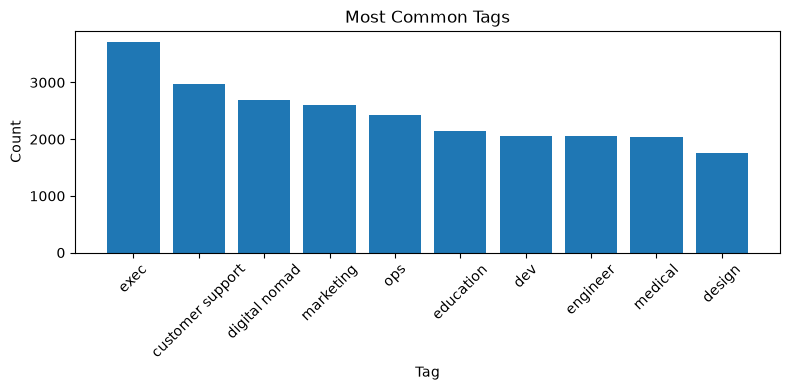

In [40]:
plt.figure(figsize=(8, 4))
plt.bar(tag_counts.head(10).index, tag_counts.head(10).values)
plt.xlabel("Tag")
plt.ylabel("Count")
plt.title("Most Common Tags")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Wrap-Up

remoteok has the most postings (5846 of 10205) and only 283 are eligible. The week this collection first found the most new postings was 2026-08-31 (1288). The most common word in eligible titles is engineer (259) and the most common tag is exec (3721).